# Stats module daft

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path
import logging


In [2]:
from src.trajectory import Trajectory
from src.core.models import KinematicProfile
from src.stats.report import TrajectoryReport


In [3]:
# Loading a trajectory 

# Init logger
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
LOG = logging.getLogger()

CSV_TRAJ = "../data/trajectories/traj_constant.csv"

# Init traj and import it
traj = Trajectory.Trajectory(LOG)
traj.from_csv(CSV_TRAJ)


# Instanciate and compute report from Trajectory object
report = TrajectoryReport(traj)
report.show_CLI()

# Export the 3-page PDF document directly
pdf_path = report.assemble_pdf("output/trajectory_report.pdf")
print(f"Report exported to: {pdf_path}")

ERROR: No such file ../data/trajectories/traj_constant.csv for trajectory CSV import !


FileNotFoundError: 

## 1. Trajectory

### 1.1 Metrics functions 

In [ ]:
def get_mean_vectorial_gravities(g_values: np.ndarray) -> np.ndarray:
    """Calcule la moyenne vectorielle cumulative au cours du temps."""
    g_cumsum = np.cumsum(g_values, axis=0)
    counts = np.arange(1, len(g_values) + 1)[:, None]
    return g_cumsum / counts

def get_residual_norm(g_values : np.ndarray) -> np.ndarray: 
    """
    Process residual norms from mean vectorial gravities
    """
    g0 = g_values[0]
    g_sums = get_mean_vectorial_gravities(g_values)
    g_norms = np.linalg.norm(g_sums, axis=1)
    return g_norms / np.linalg.norm(g0)

def get_dispersion_tensor(g_values : np.ndarray) -> np.ndarray: 
    """
    Process anisotropie matrix
    """
    norms = np.linalg.norm(g_values, axis=1, keepdims=True)
    ui = g_values / norms
    
    # Produit matriciel global (3, N) @ (N, 3) -> (3, 3)
    return (ui.T @ ui) / len(g_values)

def get_extreme_kinematics_motion(omega1: np.ndarray, omega2: np.ndarray) -> dict: 
    """
    Process extreme kinematics motions values
    """
    # Get accelerations 
    alpha1 = np.diff(omega1, axis=0)
    alpha2 = np.diff(omega2, axis=0)
    # Return max values 
    return {
        "max_alpha1" : np.max(np.abs(alpha1)),
        "max_alpha2" : np.max(np.abs(alpha2)),
        "max_omega1" : np.max(np.abs(omega1)),
        "max_omega2" : np.max(np.abs(omega2))
    }

def get_resulting_angular_speeds(Omega: np.ndarray) -> dict: 
    """
    Processing reulting angular speed from the motion angular speed Omega
    """
    Omega_norm = np.linalg.norm(Omega, axis=1)
    mean_Omega_norm = np.sqrt(
                        np.sum(Omega_norm**2) / len(Omega)
                    )
    return { 
        "mean_angular_speed" : mean_Omega_norm, 
        "max_omega_norm" : np.max(Omega_norm)
    }
        

def get_kinetic_rotation_energy(Omega: np.ndarray) -> float: 
    """
    Process kinetics rotation energy
    """
    Omega_norm = np.linalg.norm(Omega, axis=1)
    return np.sum(Omega_norm**2) / len(Omega)

In [ ]:
# Trajectory metrics computing

def compute_metrics(traj: Trajectory.Trajectory) -> dict: 
    """Compute essential Trajectory metrics to prepare matplotlib plots"""

    # Get trajectories kinematics 
    kin = traj.compute_kinematics()

    # Get metrics 
    mean_vectorial_grav = get_mean_vectorial_gravities(kin.g)
    residual_norm = get_residual_norm(kin.g)
    dispersion_tensor = get_dispersion_tensor(kin.g)
    extreme_motion = get_extreme_kinematics_motion(kin.omega1, kin.omega2)
    resulting_angular_speeds = get_resulting_angular_speeds(kin.Omega)
    kinetic_rotation_energy = get_kinetic_rotation_energy(kin.Omega)

    # Generate dict 
    values = {
        "timestamp" : kin.timestamp, 
        "omega1" : kin.omega1, 
        "omega2" : kin.omega2, 
        "theta1" : kin.theta1, 
        "theta2" : kin.theta2, 
        "Omega" : kin.Omega, 
        "Omega_dot" : kin.Omega_dot, 
        "g" : kin.g, 
        "mean_vectorial_grav" : mean_vectorial_grav, 
        "residual_norm" : residual_norm, 
        "dispersion_tensor" : dispersion_tensor, 
        "extreme_motion" : extreme_motion, 
        "resulting_angular_speeds" : resulting_angular_speeds, 
        "kinetic_rotation_energy" : kinetic_rotation_energy
    }
    return values


### 1.2 Plotting

In [ ]:

def plot_unit_sphere_g_traj(
    g: np.ndarray, timestamps: np.ndarray | None = None
) -> plt.Figure:
    """
    Display gravity vector path on the unit sphere.
    """
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection="3d")

    # Plot reference
    phi = np.linspace(0, 2 * np.pi, 30)
    theta = np.linspace(0, np.pi, 15)
    phi_grid, theta_grid = np.meshgrid(phi, theta)

    xs = np.sin(theta_grid) * np.cos(phi_grid)
    ys = np.sin(theta_grid) * np.sin(phi_grid)
    zs = np.cos(theta_grid)
    ax.plot_wireframe(xs, ys, zs, color="gray", alpha=0.15, linewidth=0.5)

    # Normalize g vectors
    norms = np.linalg.norm(g, axis=1, keepdims=True)
    g_unit = g / norms

    # Plot temporal points
    if timestamps is None:
        timestamps = np.arange(len(g))

    sc = ax.scatter(
        g_unit[:, 0],
        g_unit[:, 1],
        g_unit[:, 2],
        c=timestamps,
        cmap="viridis",
        s=10,
        alpha=0.8,
    )

    # ax.plot(
    #     g_unit[:, 0],
    #     g_unit[:, 1],
    #     g_unit[:, 2],
    #     color="black",
    #     alpha=0.2,
    #     linewidth=0.5,
    # )

    # Figure scale
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlim([-1, 1])
    ax.set_ylim([-1, 1])
    ax.set_zlim([-1, 1])
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.08)
    cbar.set_label("Time (s)")

    return fig


def plot_residual_convergence(g_residual_norms: np.ndarray, timestamp: np.ndarray) -> plt.Figure: 
    """
    Plot gravity residual norm convergence over the time
    """
    fig = plt.figure()
    plt.plot(timestamp, g_residual_norms)
    plt.xlabel("Time (s)")
    plt.ylabel("Gravity (m/s^2)")
    plt.title("Residual gravity convergence")
    return fig

def plot_angular_positions(
        theta1: np.ndarray, 
        theta2: np.ndarray, 
        timestamp: np.ndarray) -> plt.Figure: 
    """Plot motors positions over the time"""
    fig = plt.figure()
    plt.plot(timestamp, theta1, label="theta1")
    plt.plot(timestamp, theta2, label="theta2")
    plt.xlabel("Time (s)")
    plt.ylabel("Positions (rad)")
    plt.title("Axis positions")
    plt.legend()
    return fig

def plot_angular_speeds(
        omega1: np.ndarray, 
        omega2: np.ndarray, 
        timestamp: np.ndarray) -> plt.Figure: 
    """Plot axis speeds over the time"""
    fig = plt.figure()
    plt.plot(timestamp, omega1, label="omega1")
    plt.plot(timestamp, omega2, label="omega2")
    plt.xlabel("Time (s)")
    plt.ylabel("Velocity (rad/s)")
    plt.title("Axis velocities")
    plt.legend()
    return fig

def plot_gravity_components(
        g: np.ndarray, 
        timestamp: np.ndarray) -> plt.Figure: 
    """Plot gravity components over the time"""
    fig = plt.figure()
    print(g.shape)
    plt.plot(timestamp, g[:, 0], label='x')
    plt.plot(timestamp, g[:, 1], label='y')
    plt.plot(timestamp, g[:, 2], label='z')
    plt.legend()
    plt.xlabel("Time (s)")
    plt.ylabel("Coordinates (m)")
    plt.title("Gravity components evolution")
    return fig

def plot_angles_distribution_cartesian(
    theta1: np.ndarray, theta2: np.ndarray
) -> plt.Figure:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    bins = np.linspace(0, 2 * np.pi, 36)  # Bins de 10 degrés

    ticks = [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi]
    tick_labels = [r"$0$", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]

    for ax, data, title in zip(
        (ax1, ax2), (theta1, theta2), (r"$\theta_1$", r"$\theta_2$")
    ):
        ax.hist(
            data,
            bins=bins,
            density=True,
            edgecolor="white",
            linewidth=0.8,
            alpha=0.85,
        )
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels)
        ax.set_xlim(0, 2 * np.pi)
        ax.set_title(f"Distribution {title}")
        ax.grid(True, linestyle="--", alpha=0.3)

    fig.supxlabel("Angle (rad)")
    fig.supylabel("Densité de probabilité")
    fig.tight_layout()

    return fig

(12001, 3)


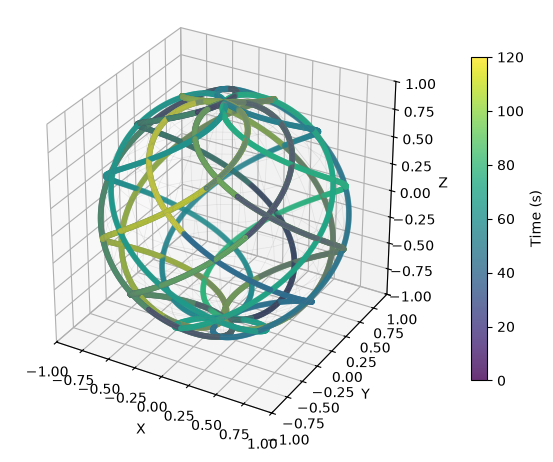

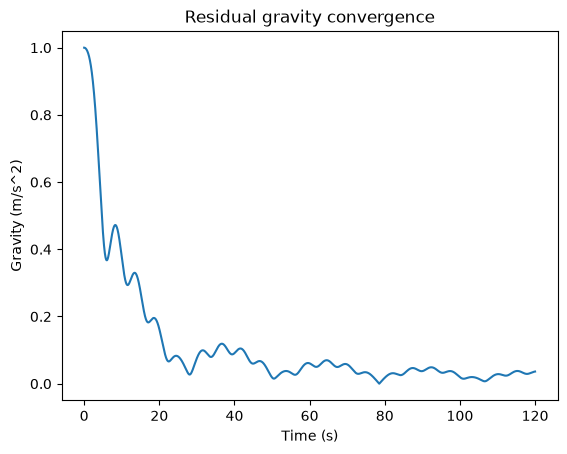

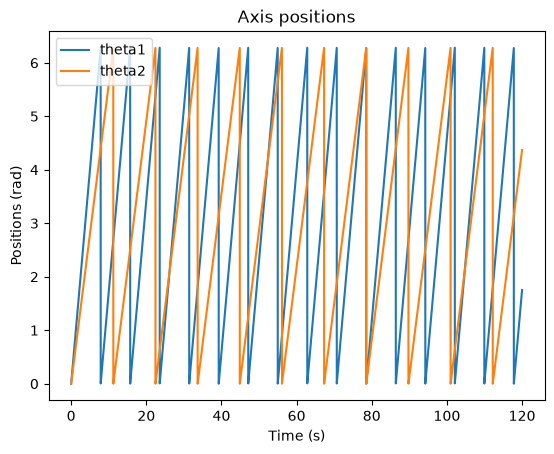

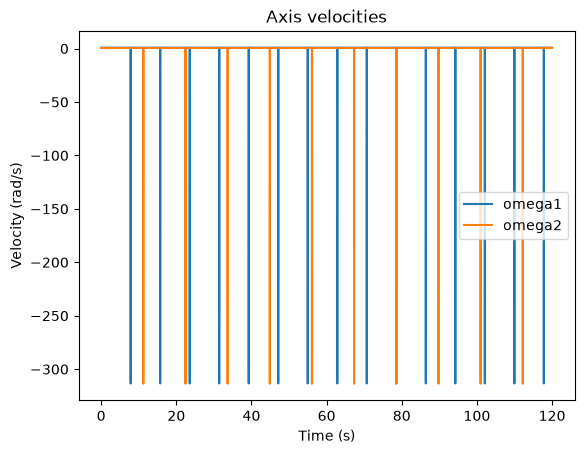

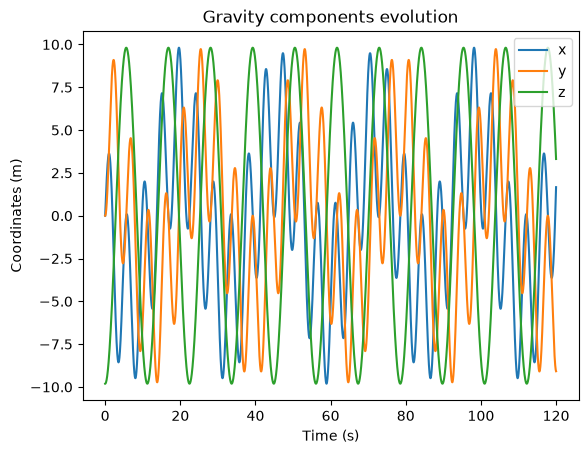

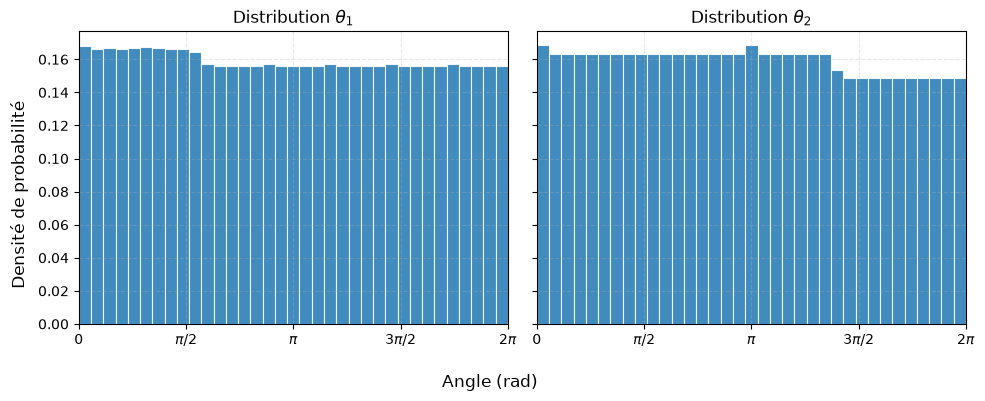

In [ ]:
# Trajectory plotting wrapper 

def generate_plot(traj : Trajectory.Trajectory) -> dict: 
    """
    Generates Matplotlib plots for a Trajectory using plotting functions. 
    """

    # Get trajectories metrics 
    metrics = compute_metrics(traj)

    # Plots 
    fig1 = plot_unit_sphere_g_traj(metrics["g"], metrics["timestamp"])
    fig2 = plot_residual_convergence(metrics["residual_norm"], metrics["timestamp"])
    fig3 = plot_angular_positions(metrics["theta1"], metrics["theta2"], metrics["timestamp"])
    fig4 = plot_angular_speeds(metrics["omega1"], metrics["omega2"], metrics["timestamp"])
    fig5 = plot_gravity_components(metrics["g"], metrics["timestamp"])
    fig6 = plot_angles_distribution_cartesian(metrics["theta1"], metrics["theta2"])

    plt.show()
    plt.close(fig1)
    plt.close(fig2)
    plt.close(fig3)
    plt.close(fig4)
    plt.close(fig5)
    plt.close(fig6)



    return None


generate_plot(traj)